In [1]:
# CELL 1: Imports and data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(
    "../data/processed/logistics_features.csv"
)

print("Dataset shape:", df.shape)

Dataset shape: (180519, 44)


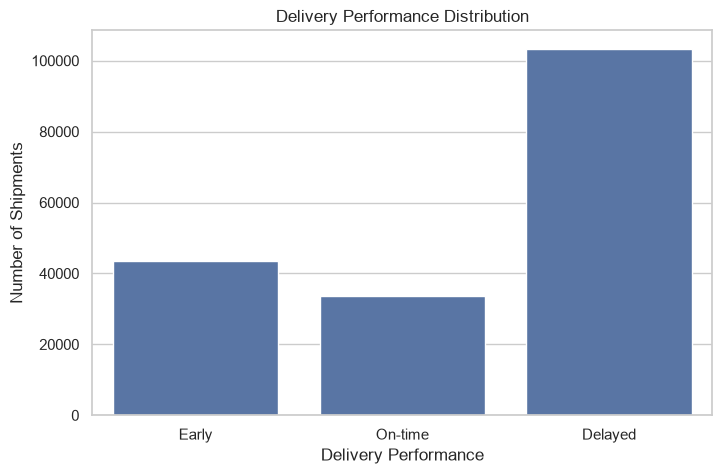

In [2]:
# CELL 2: Delivery performance distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="duration_performance",
    order=["Early", "On-time", "Delayed"]
)

plt.title("Delivery Performance Distribution")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Shipments")
plt.show()

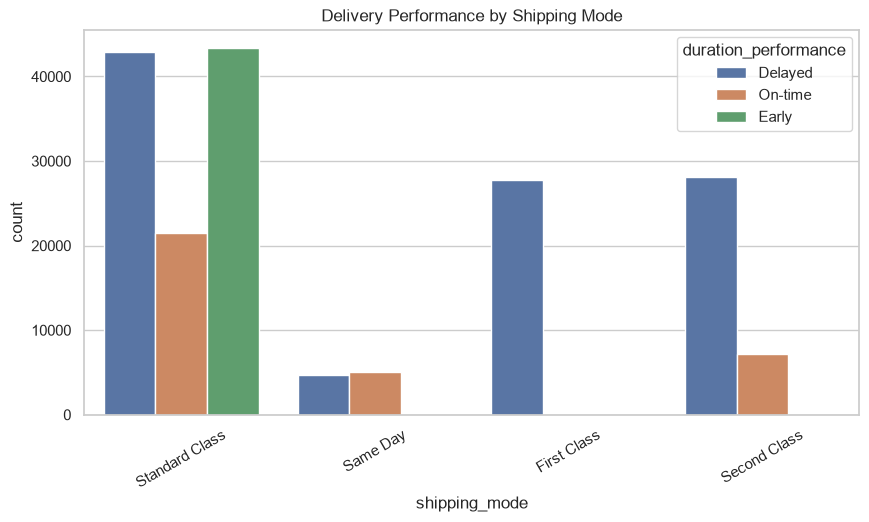

In [3]:
# CELL 3: Shipping mode analysis

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="shipping_mode",
    hue="duration_performance"
)

plt.title("Delivery Performance by Shipping Mode")
plt.xticks(rotation=30)
plt.show()

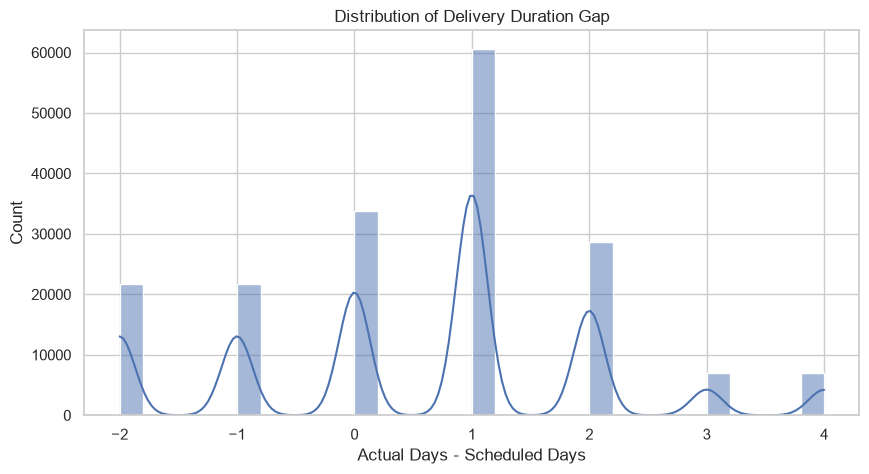

In [4]:
# CELL 4: Delay gap distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df["delivery_duration_gap"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Duration Gap")
plt.xlabel("Actual Days - Scheduled Days")
plt.show()

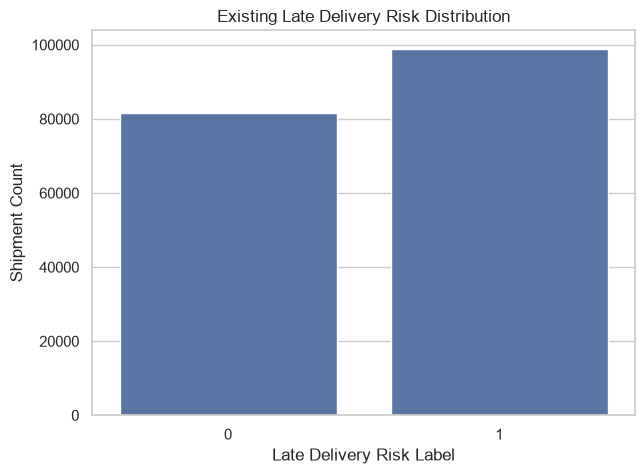

In [5]:
# CELL 5: Late delivery risk distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="late_delivery_risk"
)

plt.title("Existing Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk Label")
plt.ylabel("Shipment Count")
plt.show()

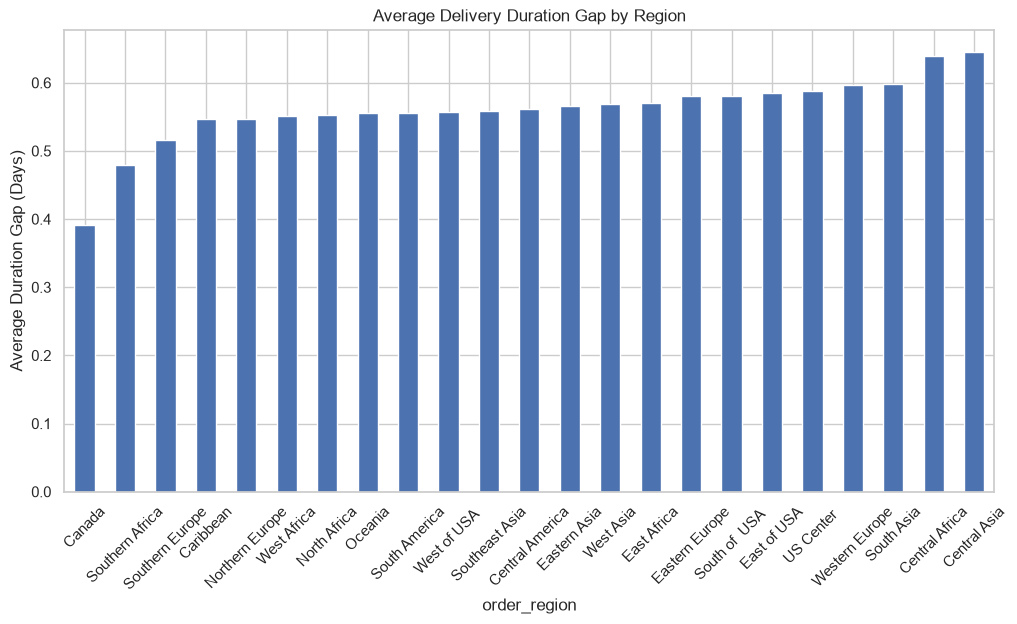

In [6]:
# CELL 6: Regional performance

regional = df.groupby(
    "order_region"
)["delivery_duration_gap"].mean().sort_values()

plt.figure(figsize=(12, 6))

regional.plot(kind="bar")

plt.title("Average Delivery Duration Gap by Region")
plt.ylabel("Average Duration Gap (Days)")
plt.xticks(rotation=45)
plt.show()

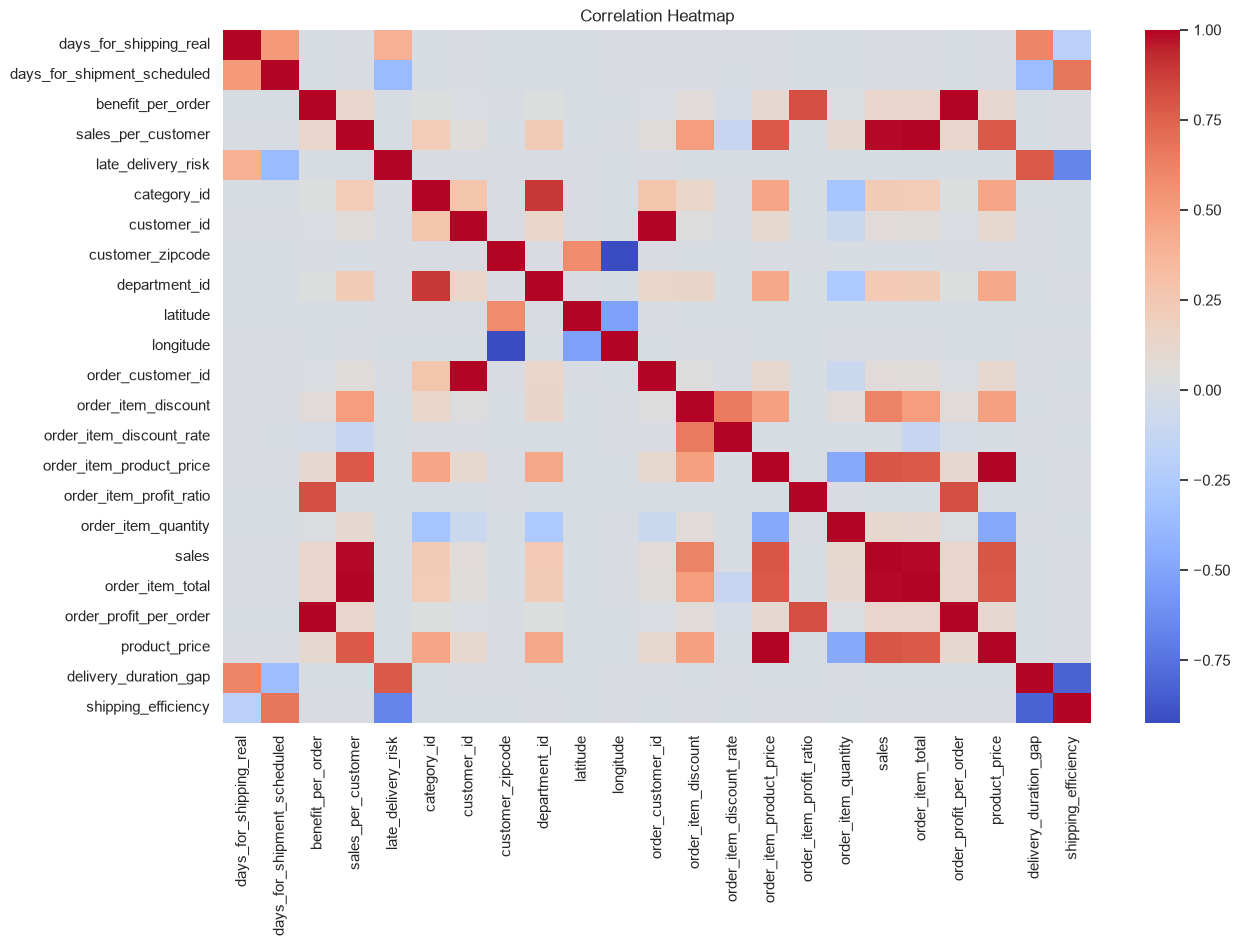

In [7]:
# CELL 7: Correlation heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 9))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap")
plt.show()

In [8]:
# CELL 8: Business summary

print("TOTAL SHIPMENTS:", len(df))

print("\nDELIVERY PERFORMANCE:")
print(df["duration_performance"].value_counts())

print("\nSHIPPING MODE:")
print(df["shipping_mode"].value_counts())

print("\nAVERAGE DELIVERY GAP:")
print(round(df["delivery_duration_gap"].mean(), 2), "days")

print("\nEXISTING LATE DELIVERY RISK:")
print(df["late_delivery_risk"].value_counts(normalize=True) * 100)

TOTAL SHIPMENTS: 180519

DELIVERY PERFORMANCE:
duration_performance
Delayed    103400
Early       43366
On-time     33753
Name: count, dtype: int64

SHIPPING MODE:
shipping_mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

AVERAGE DELIVERY GAP:
0.57 days

EXISTING LATE DELIVERY RISK:
late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64
